# Appendix C: seasonality

One composite figure (3 × 3) of the seasonal panels from four notebooks. No new analysis; each data cell is copied from its source.

| row | panels | source |
|---|---|---|
| 1 | (a) seasonal cycle of the wind-based upwelling indices (±1 std across years) | `v2.UI_comparison_winds`, seasonal-cycle-with-std cell |
|   | (b) $U^{Ek}$ vs $N_{MLD}$, (c) MLD vs $N_{MLD}$ (12-month climatologies) | `v3.UI_comparison`, top row of the N vs MLD / $U^{Ek}$ figure |
| 2 | (d) coastal, (e) offshore, (f) coastal − offshore ML heat budget | `Heat_budget_figure`, "coastal, offshore and coastal − offshore" cell |
| 3 | (g) heat budget terms vs distance from the coast, (h) winter and (i) summer volume/temperature budget of the 0–20 km box | `Coastal_box_volume_budget`, appendix pathway figure (last cell) |

In [13]:
import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow
from scipy.io import loadmat
from scipy.stats import pearsonr

NB  = Path('/gxfs_work/geomar/smomw662/NHCS/notebooks/')
MON = NB / 'monthly'
FIG = NB / 'Figures' / 'paper'
GRID_FILE = MON / 'croco_avg_Y1980M01.nc'   # copy of the first croco_avg file of /nfs/ceph_geomar/smomw398/CROCO_BioEBUS_1980_2015/OUTPUT/

mask_km = 109
lat1, lat0 = -16, -5
S_DAY, SV = 86400.0, 1e6
DAYS = np.array([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
SEAS = {'annual': list(range(1, 13)), 'JJA': [6, 7, 8], 'DJF': [12, 1, 2]}
MONTHS = list('JFMAMJJASOND')

## Helper functions

In [14]:
def coastal_band_mask(ds, var='u10', target_width_km=111):
    """
    Create a coastal band mask with uniform cross-shore width in km.
    """
    da = ds[var]
    if 'time' in da.dims:
        da = da.mean(dim='time')

    valid2d = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon = np.abs(lon_vals[1] - lon_vals[0])  # grid spacing in degrees

    # Find coastline (easternmost valid cell per row)
    band = np.zeros_like(valid2d, dtype=bool)

    for j in range(valid2d.shape[0]):
        row = valid2d[j, :]
        ocean_cols = np.where(row)[0]
        if len(ocean_cols) == 0:
            continue

        # Coast = easternmost valid cell
        i_coast = ocean_cols[-1]

        # How many cells = target_width_km at this latitude?
        A = 6371.0  # km
        dx_km = A * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))

        # Fill n_cells westward from coast
        i_start = max(i_coast - n_cells, 0)
        band[j, i_start:i_coast + 1] = True

    # Only keep cells that are actually ocean
    band = band & valid2d

    da_mask = xr.DataArray(band, dims=('lat', 'lon'),
                           coords={'lat': ds['lat'], 'lon': ds['lon']})
    return da_mask

def seasonality(data):
    return data.groupby('time.month').mean(dim='time')

def seasonal_mean_std(da, dims=None):
    """Monthly climatology and its across-years standard deviation."""
    ts = da.mean(dim=dims) if dims else da
    grp = ts.groupby('time.month')
    return grp.mean('time'), grp.std('time')

def monthly_clim(ds):
    g = ds.groupby('time.month')
    return g.mean(), g.std()

def _ptxt(pv):
    return "$p$ < 0.001" if pv < 0.001 else f"$p$ = {pv:.3f}"

## Row 1 data
(a) wind-based indices, all in m² s⁻¹ per metre of coastline (as in `UI_comparison` / `Latitudinal`), 5–16°S row means: CUTI and $W_{MLD}$ (`W_L`) from `CUTI_BEUTI_HR_L_C.nc`; AV integrated across the 111 km band × row height ÷ coastline length; $EK_t$ = cross-shore Ekman transport at the coast (already per metre of coastline).

In [15]:
path0 = '../data/'     # publication data folder
R = 6371000.0

# high-resolution CUTI, per metre of coastline (one lat_band per grid row); the file is stored N -> S
hr = xr.open_dataset( path0+'CUTI_BEUTI_HR_L_C.nc').sortby('lat_band').compute().sel(lat_band=slice(lat1, lat0))
CUTI = hr.CUTI
assert int(hr.L_coast.isnull().sum()) == 0
L  = hr.L_coast.rename(lat_band='lat')
# row height: not stored in the _C file; CUTI_BEUTI_HR_L.nc has the same rows and L_coast and stores it
dy = (xr.open_dataset(path0 + 'CUTI_BEUTI_HR_L.nc').dy.sortby('lat_band')
        .sel(lat_band=slice(lat1, lat0)).rename(lat_band='lat'))

# W_MLD per metre of coastline: CROCO W integrated over the same row strip / L_coast (= WMLD_L of UI_comparison)
W_L = hr.W_L

# AV (on CUTI's band, from AV.ipynb) per metre of coastline, as in Latitudinal: zonal integral over the 111 km band x row height / L_coast
AV = xr.open_dataset(path0 + 'AV.nc').AV.compute().sel(lat=slice(lat1, lat0))
dx = R * np.cos(np.deg2rad(AV.lat)) * np.deg2rad(1 / 12)          # m
L_av  = L.reindex(lat=AV.lat, method='nearest', tolerance=0.02)
dy_av = dy.reindex(lat=AV.lat, method='nearest', tolerance=0.02)
AV_L = ((AV * dx).sum('lon', min_count=1) * dy_av / L_av).rename('AV')   # m2/s per metre of coastline

# Ek_t: cross-shore Ekman transport at the coast, already m2/s per metre of coastline (as in Latitudinal)
Ek_t = xr.open_dataset(path0 + 'Winds_components_Lu.nc').U_ek_cross.isel(offshore=0)
Ek_t = (Ek_t.swap_dims({'coast_point': 'lat'})
         .drop_vars(['coast_point', 'lon', 'bearing', 'distance', 'f', 'offshore'])
         .rename('Ek_t')).sel(lat=slice(lat1, lat0)).compute()

# 5-16°S: plain row means of the per-metre-of-coastline series
wmld_m,  wmld_sd  = seasonal_mean_std(W_L,  'lat_band')
AV_m,    AV_sd    = seasonal_mean_std(AV_L, 'lat')
Ekt_m,   Ekt_sd   = seasonal_mean_std(Ek_t, 'lat')
CUTI_m,  CUTI_sd  = seasonal_mean_std(CUTI, 'lat_band')

WIND_SERIES = [
    (wmld_m, wmld_sd, 'black',      'o', 4, '$W_{MLD}$'),
    (AV_m,   AV_sd,   'dodgerblue', 's', 6, 'AV'),
    (Ekt_m,  Ekt_sd,  'royalblue',  'd', 6, '$EK_t$'),
    (CUTI_m, CUTI_sd, 'purple',     'o', 4, 'CUTI'),
]


(b), (c) nitrogen, as `v3.UI_comparison`: $N_{MLD}$ and MLD in the 109 km band (MLD masked with the band of the `u` field, as in v3), $U^{Ek}$ = band mean of the HR CUTI file.

In [16]:
u = xr.open_dataset(NB / 'UV_velocities.nc')[['u']].compute().transpose('time', 'lat', 'lon')
u = u.where(u != 0, np.nan)
mask = coastal_band_mask(u, 'u', mask_km).sel(lon=slice(-85, None), lat=slice(lat1, lat0))
del u

MLD = xr.open_dataset(MON / 'MLD.nc').compute()
MLD = MLD.where(mask).sel(lon=slice(-85, None), lat=slice(lat1, lat0))

N = xr.open_dataset(MON / 'Nitrogen.nc').compute()
N = N.where(N.TN_mld != 0, np.nan)
Nmask = coastal_band_mask(N, 'TN_mld', mask_km)
N = N.where(Nmask).sel(lon=slice(-85, None), lat=slice(lat1, lat0)).TN_mld
N['time'] = MLD.MLD.time            # same 432 monthly steps, different stamps

N_ts   = N.mean(dim=('lat', 'lon'))
MLD_ts = MLD.MLD.mean(dim=('lat', 'lon'))
UEK_ts = hr.U_ek.mean(dim='lat_band')

Ns, MLDs_, UEKs_ = seasonality(N_ts), seasonality(MLD_ts), seasonality(UEK_ts)

N_LABEL   = r'$N_{MLD}$ [$mmol\,N \cdot m^{-3}$]'
MLD_LABEL = r'MLD [$m$]'
UEK_LABEL = r'$U^{Ek}$ [$m^{2} \cdot s^{-1}$]'

## Row 2 data
Coastal and offshore box ML heat budget, as `Heat_budget_figure` (`Heat_budget.mat`; hmix and temp dropped, hadv = xadv + yadv).

In [17]:
mat = loadmat(MON / 'Heat_budget.mat')

terms   = ['rate', 'forc', 'xadv', 'yadv', 'vadv', 'hmix', 'vmix', 'entr', 'temp']
regions = ['coast', 'off']
time = pd.date_range("1980-01-01", periods=432, freq="MS")

data_vars = {}
for t in terms:
    cols = [np.asarray(mat[f"BUDGET_{r}_{t}"]).ravel() for r in regions]
    data_vars[t] = (("time", "region"), np.column_stack(cols).astype("float64"))
ds = xr.Dataset(data_vars, coords={"time": time, "region": regions})

ds_clean = ds.drop_vars(['hmix', 'temp'])
ds_clean = ds_clean.assign(hadv=ds_clean.xadv + ds_clean.yadv).drop_vars(['xadv', 'yadv'])   # horizontal advection
coast_m, coast_s = monthly_clim(ds_clean.sel(region='coast'))
off_m,   off_s   = monthly_clim(ds_clean.sel(region='off'))
dif_m,   dif_s   = monthly_clim(ds_clean.sel(region='coast') - ds_clean.sel(region='off'))
for d in (coast_m, coast_s, off_m, off_s, dif_m, dif_s):
    for v in d.data_vars:
        d[v] = d[v] * 86400

hb_colors = {'rate': 'black', 'forc': 'mediumpurple', 'hadv': 'steelblue',
             'vadv': 'forestgreen', 'vmix': 'tab:red', 'entr': 'chocolate'}
hb_labels = {'rate': 'Tendency', 'forc': 'forc', 'hadv': 'hadv',
             'vadv': 'vadv', 'vmix': 'vmix', 'entr': 'entr'}

## Row 3 data
As `Coastal_box_volume_budget`.
(g) Test A cross-shore profile (REF, 5–16°S, annual mean) from the offline ML budget; needs the CROCO grid of the first `croco_avg` file (local copy in `monthly/`) (same grid, box and coast distance as that notebook).

In [18]:
BOX = dict(lat=(-20.0, -2.0), lon=(-90.0, -70.0))
g = xr.open_dataset(GRID_FILE)
lat_1d = g['lat_rho'].isel(xi_rho=0).values
lon_1d = g['lon_rho'].isel(eta_rho=0).values
J = np.where((lat_1d >= BOX['lat'][0]) & (lat_1d <= BOX['lat'][1]))[0]
I = np.where((lon_1d >= BOX['lon'][0]) & (lon_1d <= BOX['lon'][1]))[0]
JS, IS = slice(J[0] - 1, J[-1] + 2), slice(I[0] - 1, I[-1] + 2)
pm, pn, mask_rho = g['pm'].values[JS, IS], g['pn'].values[JS, IS], g['mask_rho'].values[JS, IS]
lat_b, lon_b = lat_1d[JS], lon_1d[IS]
g.close()
assert np.all(np.diff(lat_b) > 0), 'rows must run south -> north'
ocean = mask_rho == 1
area_b = 1 / (pm * pn)

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.deg2rad(lat1), np.deg2rad(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.deg2rad(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

coast_lon = np.array([lon_b[np.where(ocean[j])[0][-1]] if ocean[j].any() else np.nan for j in range(len(lat_b))])
LAT2, LON2 = np.meshgrid(lat_b, lon_b, indexing='ij')
okc = np.isfinite(coast_lon)
dist = np.full(LAT2.shape, np.nan)
for j in range(len(lat_b)):
    dist[j] = haversine_km(LAT2[j][:, None], LON2[j][:, None], lat_b[okc][None, :], coast_lon[okc][None, :]).min(axis=1)
dist[~ocean] = np.nan

def appendix_profile():
    mlx = xr.open_dataset(NB / 'Heat_budget_ML_offline.nc')[['T_hbl', 'forc_hbl', 'xadv_hbl', 'yadv_hbl', 'vadv_hbl',
                                                             'vmix_hbl', 'hmix_hbl']].load()
    rot = xr.open_dataset(NB / 'Heat_budget_ML_rotation.nc')[['aadv']].load()
    pwm = xr.open_dataset(NB / 'Upwelling_pathway_maps.nc')[['cadv']].load()
    tt = mlx.time
    rot = rot.sel(lat=mlx.lat, lon=mlx.lon, method='nearest').assign_coords(lat=mlx.lat, lon=mlx.lon, time=tt)
    pwm = pwm.sel(lat=mlx.lat, lon=mlx.lon, method='nearest').assign_coords(lat=mlx.lat, lon=mlx.lon, time=tt)
    t = (tt - tt[0]).values / np.timedelta64(1, 's')
    rate = xr.DataArray(np.gradient(mlx.T_hbl.values, t, axis=mlx.T_hbl.dims.index('time')),
                        dims=mlx.T_hbl.dims, coords=mlx.T_hbl.coords)
    bud = xr.Dataset({'rate': rate, 'forc': mlx.forc_hbl, 'hadv': mlx.xadv_hbl + mlx.yadv_hbl,
                      'vadv': mlx.vadv_hbl, 'hvmix': mlx.vmix_hbl + mlx.hmix_hbl}) * S_DAY
    bud['entr'] = bud.rate - (bud.forc + bud.hadv + bud.vadv + bud.hvmix)
    bud['vcool'] = bud.vadv + bud.entr                        # − = cooling, same convention as the other terms
    bud = bud.mean('time')                                    # annual mean of all 432 months
    sl = (slice(1, -1), slice(1, -1))
    cdm = dict(dims=('lat', 'lon'), coords={'lat': mlx.lat, 'lon': mlx.lon})
    areaA, distA, oceanA = (xr.DataArray(a[sl], **cdm) for a in (area_b, dist, ocean))
    reg = (mlx.lat >= -16) & (mlx.lat <= -5)
    edges = [0, 10, 20, 30, 50, 75, 100, 150, 200]           # DIST_BINS of Test A
    rows = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = oceanA & reg & (distA >= a) & (distA < b)
        w = areaA.where(m, 0.0)
        r = {k: float(bud[k].weighted(w).mean(('lat', 'lon'))) for k in ['vcool', 'hadv', 'forc', 'hvmix']}
        r.update(n=int(m.sum()), mid_km=(a + b) / 2)
        rows.append(pd.Series(r, name=f'{a}–{b}'))
    return pd.DataFrame(rows)

PA = appendix_profile()
display(PA.round(3))

,vcool,hadv,forc,hvmix,n,mid_km
0–10,-0.140,-0.046,0.341,-0.156,279.0,5.0
10–20,-0.040,-0.075,0.208,-0.092,156.0,15.0
20–30,-0.034,-0.068,0.179,-0.076,213.0,25.0
30–50,-0.020,-0.065,0.146,-0.061,360.0,40.0
50–75,-0.015,-0.056,0.120,-0.049,450.0,62.5
75–100,-0.013,-0.048,0.101,-0.040,440.0,87.5
100–150,-0.007,-0.044,0.081,-0.030,878.0,125.0
150–200,-0.003,-0.038,0.060,-0.019,863.0,175.0


(h), (i) volume budget of box I (0–20 km, 5–16°S, α = 1/2) from `Coastal_box_volume.nc`; climatology, `budget()` and the face temperatures `face_T()` as in that notebook.

In [19]:
vb = xr.open_dataset(NB / 'Coastal_box_volume.nc').load()
C = vb.groupby('time.month').mean('time')

def ddt_clim(x):
    # centred cyclic derivative along 'month' (per second)
    dt = np.array([(DAYS[(m - 1) % 12] / 2 + DAYS[m] + DAYS[(m + 1) % 12] / 2) for m in range(12)]) * S_DAY
    return (x.roll(month=-1, roll_coords=False) - x.roll(month=1, roll_coords=False)) / xr.DataArray(dt, dims='month', coords={'month': x.month})

def budget(c, dom, al):
    q = c.sel(domain=dom)
    qa = q.sel(alpha=al)
    dVdt, dZdt = ddt_clim(q.Sh), ddt_clim(q.Sz)
    o = xr.Dataset()
    o['base_w'], o['base_dhdt'], o['base_ugradh'], o['base_zeta'] = q.Wb, dVdt, q.UGHb, -(dZdt + q.UGZb)
    o['Q_base'] = o.base_w + o.base_dhdt + o.base_ugradh + o.base_zeta
    o['mid_w'], o['mid_dhdt'], o['mid_ugradh'], o['mid_zeta'] = qa.Wm, al * dVdt, al * qa.UGHm, -(dZdt + qa.UGZm)
    o['Q_mid'] = o.mid_w + o.mid_dhdt + o.mid_ugradh + o.mid_zeta
    for lay in ['L', 'U']:
        for f in ['off', 'N', 'S']:
            o[f'Q_{f}_{lay}'] = qa.Q.sel(layer=lay, face=f)
    o['dV_dt'], o['dVL_dt'], o['dVU_dt'] = dVdt, (1 - al) * dVdt, al * dVdt
    latL = o.Q_off_L + o.Q_N_L + o.Q_S_L
    latU = o.Q_off_U + o.Q_N_U + o.Q_S_U
    o['Q_base_res'] = dVdt + latL + latU
    o['Q_mid_res'] = al * dVdt + latU
    o['res_base'] = o.Q_base - o.Q_base_res
    o['res_mid'] = o.Q_mid - o.Q_mid_res
    o['A'] = q.A
    return o

MAIN = 'W20 5–16°S'
B0 = budget(C, MAIN, 0.5)
cq = C.sel(domain=MAIN, alpha=0.5)

def face_T(mm):
    q = cq.sel(month=mm).mean('month')
    b = B0.sel(month=mm).mean('month')
    FT, Q = q.FT, q.Q
    T = {'base (in)': float(q.WbT / q.Wb), 'mid-level': float(q.WmT / q.Wm),
         'offshore, lower half': float(FT.sel(layer='L', face='off') / Q.sel(layer='L', face='off')),
         'offshore, upper half': float(FT.sel(layer='U', face='off') / Q.sel(layer='U', face='off')),
         'box SST': float(q.SST_s / q.A)}
    V = {'base (in)': float(b.Q_base), 'mid-level': float(b.Q_mid), 'offshore, lower half': float(b.Q_off_L),
         'offshore, upper half': float(b.Q_off_U)}
    return T, V

FT_T, FT_V = {}, {}
for sname, mm in SEAS.items():
    FT_T[sname], FT_V[sname] = face_T(mm)

def season_mean(o, mm):
    return o.sel(month=mm).mean('month')

# geometry and arrow scale of Coastal_box_diagram
QMAX = max(FT_V['JJA']['base (in)'], FT_V['DJF']['base (in)']) / SV
K = 0.22 / QMAX                                  # data units of shaft width per Sv (both panels, no minimum width)
HW = 1.7                                         # head width / shaft width
C_UP, C_OUT, C_AL = 'k', 'tab:blue', '0.4'       # upward fluxes black, offshore blue, alongshore grey
BW, BH = 1.0, 2.0
X_ARR = 0.78
X_TIP = -0.95
pd.DataFrame({s: {**{f'Q {k} [Sv]': v / SV for k, v in FT_V[s].items()}, **{f'T {k} [°C]': v for k, v in FT_T[s].items()}}
              for s in ['JJA', 'DJF']}).round(2)

,JJA,DJF
Q base (in) [Sv],1.99,0.95
Q mid-level [Sv],1.14,0.59
"Q offshore, lower half [Sv]",0.89,0.40
"Q offshore, upper half [Sv]",1.16,0.59
T base (in) [°C],15.72,17.79
T mid-level [°C],16.06,17.93
"T offshore, lower half [°C]",16.34,18.85
"T offshore, upper half [°C]",16.39,18.83
T box SST [°C],16.40,19.25


## Panel functions

In [20]:
LABEL_FS = 16     # axis labels (all line/scatter panels)
TICK_FS  = 16    # tick labels
TITLE_FS = 16     # panel titles (a)–(i)
HB_LEG_FS = 15    # legend of the heat-budget row (d)–(f)
BOX_DFS  = 6    # box panels (h, i): all text inside the boxes is this much larger than fs_box

def plot_wind_indices(ax, fs):
    for m, sd, color, marker, ms, label in WIND_SERIES:
        ax.plot(m.month, m, color=color, lw=2, marker=marker, ms=ms, label=label)
        ax.fill_between(m.month, m - sd, m + sd, color=color, alpha=0.15, lw=0, zorder=0)
    ax.set_ylabel('$m^{2} \\cdot s^{-1}$', fontsize=LABEL_FS)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.set_xlim(0.5, 12.5)
    ax.tick_params(axis='both', labelsize=TICK_FS, direction='in', size=6, width=1.5)
    ax.legend(fontsize=fs - 1, ncol=2, frameon=False, loc='lower right')
    # the bands are wider than the means
    lo = min(float((m - sd).min()) for m, sd, *_ in WIND_SERIES)
    hi = max(float((m + sd).max()) for m, sd, *_ in WIND_SERIES)
    pad = 0.08 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)

def plot_seasonal_scatter(ax, xs_seas, ys_seas, xlabel, ylabel, fs):
    months = np.arange(1, 13)
    xv, yv = xs_seas.values, ys_seas.values
    ax.scatter(xv, yv, c=months, cmap='twilight', s=90, zorder=3, edgecolors='k', linewidths=0.5)
    ax.plot(xv, yv, color='grey', lw=1, zorder=2)
    for m, xm, ym in zip(months, xv, yv):
        ax.annotate(pd.Timestamp(2000, m, 1).strftime('%b'), (xm, ym),
                    textcoords='offset points', xytext=(6, 4), fontsize=fs - 1)
    r, p = pearsonr(xv, yv)
    ax.text(0.04, 0.96, f"$r^2$ = {r**2:.2f}", transform=ax.transAxes, va='top', ha='left',
            fontsize=fs, bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax.set_xlabel(xlabel, fontsize=LABEL_FS)
    ax.set_ylabel(ylabel, fontsize=LABEL_FS)
    ax.tick_params(labelsize=TICK_FS)
    return r, p

def plot_terms_titled(ax, mean_ds, std_ds, colors, labels, title, fs):
    months_ = mean_ds['month'].values
    for var, color in colors.items():
        if var not in mean_ds.data_vars:
            continue
        m = mean_ds[var].values
        s = std_ds[var].values
        ax.plot(months_, m, color=color, lw=2, label=labels[var])
        ax.fill_between(months_, m - s, m + s, color=color, alpha=0.2, linewidth=0)
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_title(title, loc='left', fontsize=TITLE_FS, fontweight='bold')
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.set_xlim([1, 12])
    ax.tick_params(labelsize=TICK_FS)

def align_zeros(axes):
    lims = [a.get_ylim() for a in axes]
    fracs = [-ymin / (ymax - ymin) for ymin, ymax in lims]
    target = max(fracs)
    for a, (ymin, ymax) in zip(axes, lims):
        new_ymin = target * ymax / (target - 1)
        a.set_ylim(min(new_ymin, ymin), ymax)

A_CURVES = [('forc', 'surface forcing', 'mediumpurple', 1.6), ('hadv', 'horizontal advection', 'steelblue', 1.6),
            ('vcool', 'vertical cooling', 'k', 2.6), ('hvmix', 'vmix + hmix', 'tab:red', 1.6)]     # colours of Figure 4

def plot_profile(ax, fs):
    x = PA.mid_km.values
    for k, lab, col, lw in A_CURVES:
        ax.plot(x, PA[k], 'o-', color=col, lw=lw, ms=4, label=lab)
    ax.axhline(0, color='0.4', lw=0.6)
    ax.axvspan(0, 20, color='gold', alpha=0.2, lw=0, label='0–20 km (box in h, i)')
    ax.set_xlim(0, 200)
    ax.annotate('warming', (2, 0), xytext=(0, 2.5), textcoords='offset points', ha='left', va='bottom',
                fontsize=fs - 2, color='0.45')
    ax.annotate('cooling', (2, 0), xytext=(0, -2.5), textcoords='offset points', ha='left', va='top',
                fontsize=fs - 2, color='0.45')
    ax.set_xlabel('distance from the coast [km]', fontsize=LABEL_FS)
    ax.set_ylabel('°C d$^{-1}$', fontsize=LABEL_FS)
    ax.tick_params(labelsize=TICK_FS)
    ax.legend(loc='best', fontsize=fs - 1, framealpha=0.95)

# box data for panel_app: face temperatures / volume fluxes, budget, arrow scale and the width label
BOX_20KM = dict(T=FT_T, V=FT_V, B=B0, K=K, label='20 km')

def panel_app(ax, s, title, fs, bw=BW, x_arr=X_ARR, x_tip=X_TIP, rises_lines=2, note='', box=None):
    # copy of panel_app() of Coastal_box_volume_budget (panel() of Coastal_box_diagram with the geometry as arguments)
    fs = fs + BOX_DFS
    box = box or BOX_20KM
    T, V = box['T'][s], {k: v / SV for k, v in box['V'][s].items()}
    b = season_mean(box['B'], SEAS[s])
    al_in = {'L': -float(b.Q_N_L + b.Q_S_L) / SV, 'U': -float(b.Q_N_U + b.Q_S_U) / SV}   # net alongshore INTO each half
    labels, statics, obst, exempt = [], [], [], []
    ax.add_patch(Rectangle((0, 0), bw, 1, fc='#d6e6f5', ec='none'))
    ax.add_patch(Rectangle((0, 1), bw, 1, fc='#eef5fb', ec='none'))
    edges = {}
    for name, xs, ys in [('bottom', [0, bw], [0, 0]), ('mid', [0, bw], [1, 1]), ('top', [0, bw], [2, 2]),
                         ('west', [0, 0], [0, 2]), ('east', [bw, bw], [0, 2])]:
        edges[name] = ax.plot(xs, ys, color='k', lw=1.2)[0]; obst.append(edges[name])
    bar = Rectangle((bw, -0.12), 0.13, BH + 0.2, fc='0.6', ec='none'); ax.add_patch(bar); obst.append(bar)
    ax.text(bw + 0.065, 0.95, 'coast', rotation=90, ha='center', va='center', fontsize=fs - 1, color='white', fontweight='bold')
    for y, lab in [(2.0, 'surface'), (1.0, '−MLD/2'), (0.0, '−MLD')]:
        obst += ax.plot([-0.06, 0], [y, y], color='k', lw=1)
        statics.append(ax.text(-0.08, y, lab, ha='right', va='center', fontsize=fs - 1.5))
    statics.append(ax.text(0.04, 1.95, 'upper half', ha='left', va='top', fontsize=fs - 1, style='italic', color='0.3'))
    statics.append(ax.text(0.04, 0.05, 'lower half', ha='left', va='bottom', fontsize=fs - 1, style='italic', color='0.3'))
    statics.append(ax.text(x_tip - 0.05, 2.42, '← offshore', ha='left', va='center', fontsize=fs, style='italic'))
    statics.append(ax.text(bw, 2.42, f"{box['label']} →", ha='right', va='center', fontsize=fs, style='italic'))
    statics.append(ax.text(0.5 * bw, 2.13, f"surface: SST = {T['box SST']:.1f} °C", ha='center', va='bottom', fontsize=fs - 0.5))
    def arr(x, y, dx, dy, q, col):
        w = box['K'] * abs(q)
        a = FancyArrow(x, y, dx, dy, width=w, head_width=HW * w, head_length=0.14, length_includes_head=True, color=col, ec='none')
        ax.add_patch(a); obst.append(a)
        return w
    lab = lambda q, t: f"{q:.2f} Sv ({t:.1f} °C)"
    arr(x_arr, -0.95, 0, 1.0, V['base (in)'], C_UP)
    labels.append(ax.text(x_arr, -1.0, 'in: ' + lab(V['base (in)'], T['base (in)']), ha='center', va='top', fontsize=fs, color=C_UP))
    if note:                                         # e.g. 'strong upwelling', one line below the inflow label
        labels.append(ax.annotate(note, (x_arr, -1.0), xytext=(0, -1.3 * fs), textcoords='offset points',
                                  ha='center', va='top', fontsize=fs, fontweight='bold', color=C_UP))
    w = arr(x_arr, 0.55, 0, 0.8, V['mid-level'], C_UP)
    sep = '\n' if rises_lines == 3 else ' '
    tm = ax.text(x_arr - 0.5 * HW * w - 0.04, 1.0, f"rises:{sep}{V['mid-level']:.2f} Sv\n({T['mid-level']:.1f} °C)",
                 ha='right', va='center', fontsize=fs - 0.5, color=C_UP, linespacing=1.1,
                 bbox=dict(fc='white', ec='none', pad=1.5))
    labels.append(tm); exempt.append((tm, edges['mid']))
    for y, key in [(0.45, 'offshore, lower half'), (1.5, 'offshore, upper half')]:
        w = arr(0.0, y, x_tip, 0, V[key], C_OUT)
        # right-aligned just west of the box edge (centred on the arrow it ran into the box at larger fonts)
        labels.append(ax.text(-0.04, y + 0.5 * HW * w + 0.03, lab(V[key], T[key]), ha='right', va='bottom',
                              fontsize=fs, color=C_OUT))
    for y, lay in [(1.62, 'U'), (0.3, 'L')]:
        labels.append(ax.text(bw - 0.04, y, f"{al_in[lay]:+.2f} Sv\nalongshore", ha='right', va='center',
                              fontsize=fs - 2.5, color=C_AL, linespacing=1.1))
    ax.set_xlim(x_tip - 0.1, bw + 0.4); ax.set_ylim(-1.3, 2.55); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=TITLE_FS, fontweight='bold')
    # labels that reach past the axes edge would make constrained layout shrink the box: keep them out of the layout
    for t in ax.texts:
        t.set_in_layout(False)
    return labels, statics, obst, exempt

def collisions(fig, parts):
    r = fig.canvas.get_renderer()
    hits = []
    for ax, (labels, statics, obst, exempt) in parts:
        texts = labels + statics
        for i, t in enumerate(texts):
            bt = t.get_window_extent(r).padded(1)
            for o in obst:
                if (t, o) in exempt:
                    continue
                if bt.overlaps(o.get_window_extent(r)):
                    hits.append((ax.get_title(), t.get_text().replace('\n', ' '), type(o).__name__))
            for u_ in texts[i + 1:]:
                if bt.overlaps(u_.get_window_extent(r)):
                    hits.append((ax.get_title(), t.get_text().replace('\n', ' '), 'text: ' + u_.get_text().replace('\n', ' ')))
    return hits

## Figure (`Figures/paper/Appendix_C.pdf`)
Three independent rows (subfigures); row 3 is split 1 : 2 so that (g), (h), (i) are three equal columns, as in `Appendix_pathway`. In rows 1 and 2 each panel has its own 1/3-width subfigure, like (g), so all panels have the width of (g).
The box panels keep the fallback of `Coastal_box_volume_budget`: if a label overlaps an arrow, edge or another label, the font
shrinks (11 → 8 pt), then the offshore arrows are lengthened, then the box is widened.

box geometry 0 (as Coastal_box_diagram), box font size 8 (+ BOX_DFS = 14): REMAINING OVERLAPS: [('(h) Winter (JJA)', '+0.05 Sv alongshore', 'text: lower half'), ('(h) Winter (JJA)', 'lower half', 'FancyArrow'), ('(i) Summer (DJF)', '+0.01 Sv alongshore', 'text: lower half')]
N_MLD vs U_ek (seasonal): r = +0.99, r2 = 0.98, p = 5.9e-10, n = 12
N_MLD vs MLD  (seasonal): r = +0.93, r2 = 0.87, p = 9.9e-06, n = 12


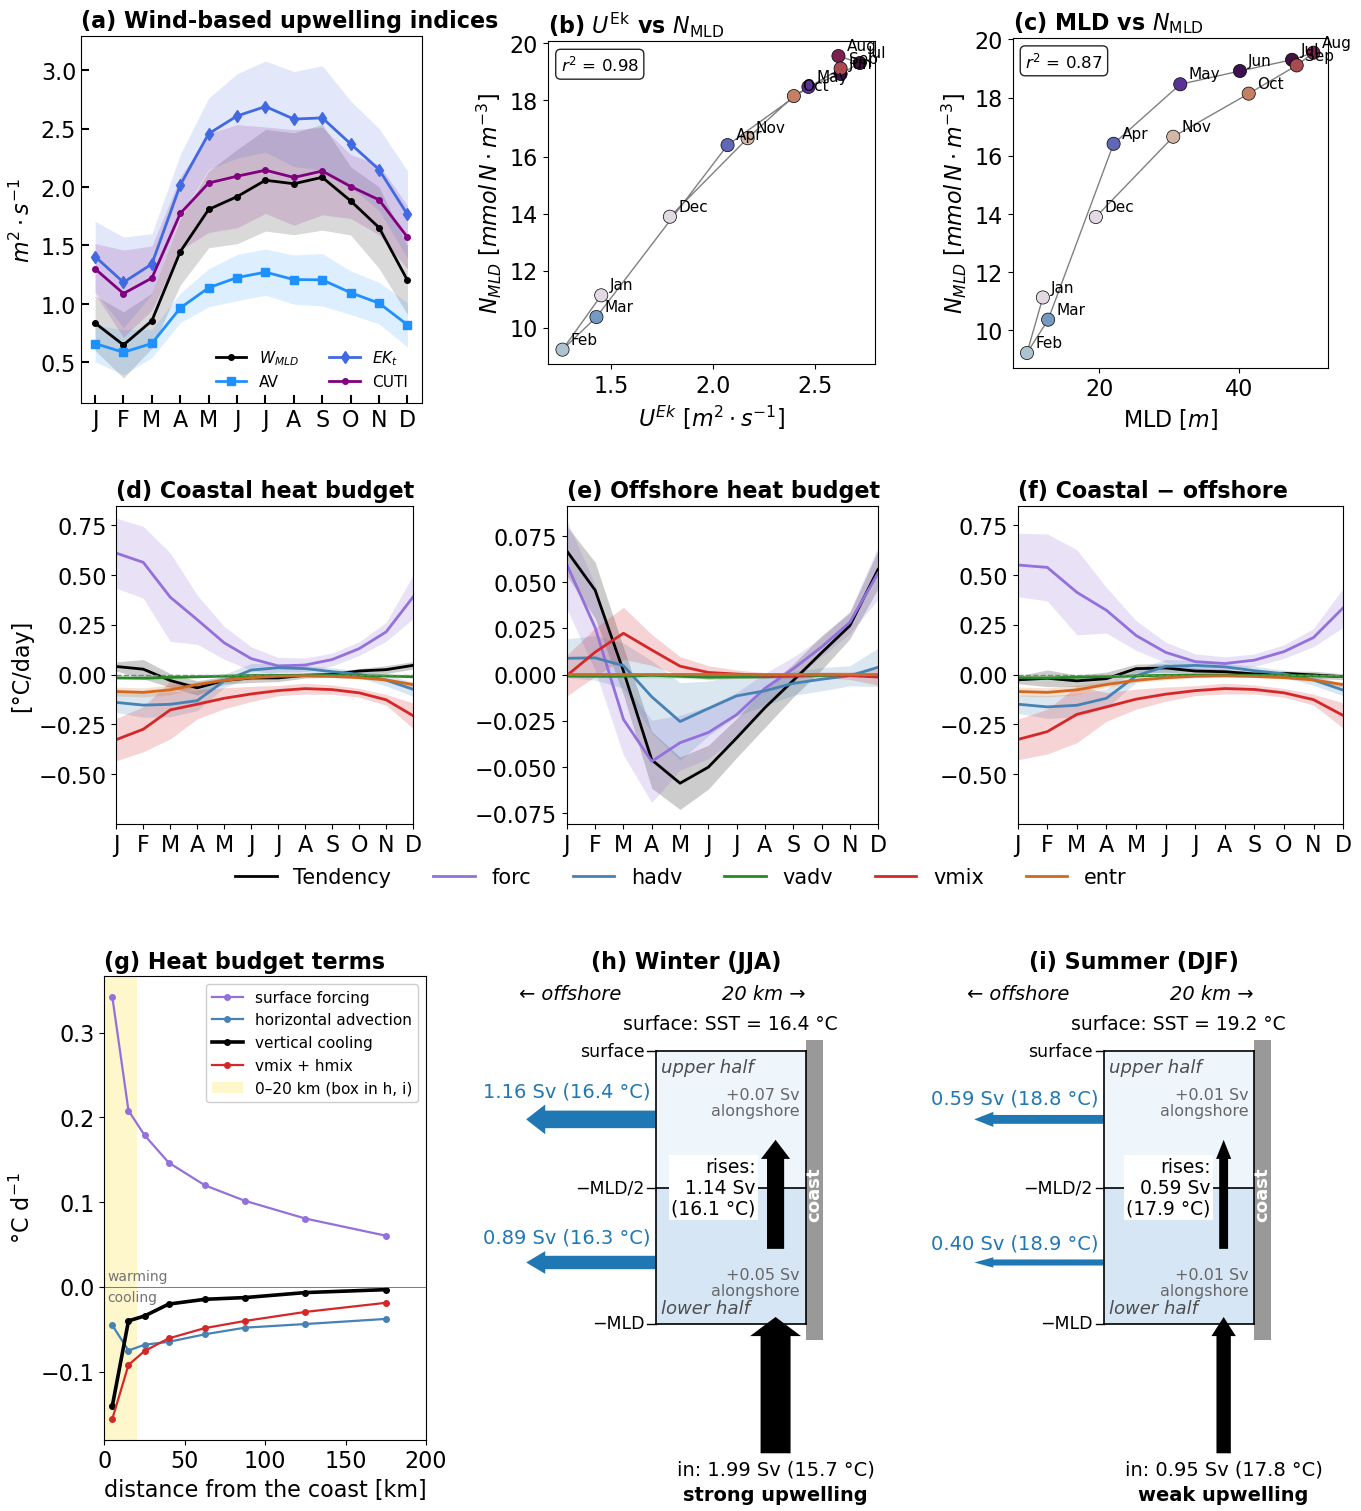

In [21]:
FS = 12
BOX_FS = [11, 10.5, 10, 9.5, 9, 8.5, 8]   # box label sizes tried, largest first
PANEL_WSPACE = 0.1     # gap between the panel subfigures of rows 1 and 2 (fraction of a panel width);
                        # larger -> narrower panels. 0.08 ~ the extra right margin (g) gets from its long title
# box geometry fixed to that of Coastal_box_diagram (no fallback to longer arrows / wider boxes: those widen the
# x-range and make the box look smaller); 'rises' label on three lines so it clears the west edge
BOX_W = 1.1 * BW      # box width: 1.1 x that of Coastal_box_diagram; upward arrows keep their distance from the coast
GEOS = [dict(bw=BOX_W, x_arr=BOX_W - (BW - X_ARR), x_tip=X_TIP, rises_lines=3)]

def draw_appendix_C(fs_box, geo, box=None):
    fig = plt.figure(figsize=(18*0.75, 20*0.75), layout='constrained')
    sf1, sf2, sf3 = fig.subfigures(3, 1, height_ratios=[1, 1, 1.3], hspace=0.08)   # hspace: gap between rows
    # rows 1 and 2: one subfigure per panel (1/3 of the width each), built like (g) in row 3,
    # so the panels get the width of (g)
    a, b, c = [s.subplots() for s in sf1.subfigures(1, 3, wspace=PANEL_WSPACE)]
    d, e, f = [s.subplots() for s in sf2.subfigures(1, 3, wspace=PANEL_WSPACE)]

    # ---------- row 1: wind-based indices, nitrogen ----------
    plot_wind_indices(a, FS)
    a.set_title('(a) Wind-based upwelling indices', loc='left', fontsize=TITLE_FS, fontweight='bold')
    stats_N = {}
    stats_N['U_ek'] = plot_seasonal_scatter(b, UEKs_, Ns, UEK_LABEL, N_LABEL, FS)
    b.set_title(r'(b) $U^{\mathrm{Ek}}$ vs $N_{\mathrm{MLD}}$', loc='left', fontsize=TITLE_FS, fontweight='bold')
    stats_N['MLD'] = plot_seasonal_scatter(c, MLDs_, Ns, MLD_LABEL, N_LABEL, FS)
    c.set_title(r'(c) MLD vs $N_{\mathrm{MLD}}$', loc='left', fontsize=TITLE_FS, fontweight='bold')

    # ---------- row 2: heat budget, coastal / offshore / coastal − offshore ----------
    plot_terms_titled(d, coast_m, coast_s, hb_colors, hb_labels, '(d) Coastal heat budget', FS)
    plot_terms_titled(e, off_m,   off_s,   hb_colors, hb_labels, '(e) Offshore heat budget', FS)
    plot_terms_titled(f, dif_m,   dif_s,   hb_colors, hb_labels, '(f) Coastal − offshore', FS)
    f.sharey(d)
    d.set_ylabel('[°C/day]', fontsize=LABEL_FS)
    align_zeros([d, e])
    handles, labels = d.get_legend_handles_labels()
    # one-line legend on the row-2 subfigure (not on an axes, so it does not change the panel widths)
    sf2.legend(handles, labels, ncol=len(hb_colors), loc='outside lower center', frameon=False, fontsize=HB_LEG_FS)

    # ---------- row 3: cross-shore profile, box budget winter / summer ----------
    sfa, sfb = sf3.subfigures(1, 2, width_ratios=[1, 2])
    g_ = sfa.subplots()
    plot_profile(g_, FS)
    g_.set_title('(g) Heat budget terms', loc='left', fontsize=TITLE_FS, fontweight='bold')
    h, i = sfb.subplots(1, 2)
    parts = [(h, panel_app(h, 'JJA', '(h) Winter (JJA)', fs_box, note='strong upwelling', box=box, **geo)),
             (i, panel_app(i, 'DJF', '(i) Summer (DJF)', fs_box, note='weak upwelling', box=box, **geo))]
    return fig, parts, stats_N

done = False
for gi, geo in enumerate(GEOS):
    for fs_box in BOX_FS:
        fig, parts, stats_N = draw_appendix_C(fs_box, geo)
        fig.canvas.draw()
        hits = collisions(fig, parts)
        done = not hits or (gi == len(GEOS) - 1 and fs_box == BOX_FS[-1])
        if done:
            break                                 # keep the last attempt open so it is displayed
        plt.close(fig)
    if done:
        break
print(f"box geometry {gi} ({'as Coastal_box_diagram' if gi == 0 else geo}), box font size {fs_box} (+ BOX_DFS = {fs_box + BOX_DFS}): "
      + ('no label overlaps an arrow, box edge, depth tick, the coast bar or another label' if not hits
         else f'REMAINING OVERLAPS: {hits}'))
for k, (r, p) in stats_N.items():
    print(f"N_MLD vs {k:4s} (seasonal): r = {r:+.2f}, r2 = {r**2:.2f}, p = {p:.1e}, n = 12")

# fig.savefig(FIG / 'Appendix_C.pdf', bbox_inches='tight')
# fig.savefig(FIG / 'Appendix_C.png', dpi=300, bbox_inches='tight')
plt.show()

---
## Same figure with the 1° box in (h), (i) (`Figures/paper/Appendix_C_1deg.pdf`)
Only the boxes change: (h), (i) show the paper's 1° coastal band (REF mask, 5–16°S) instead of the 0–20 km box I, from
`Coastal_box_1degree_band.nc`, as Figure A (`Coastal_box_band_diagram`) of `Coastal_box_volume_budget`: `budget_band()`,
base temperature = upward part of the point-wise flux q_b (inflow), mid-level temperature weighted by the point-wise q_m,
lateral faces u T dz dl per layer; arrow scale K = 0.22 / max(Q_base JJA, DJF) of the band. Style, sizes and the other
panels are those of the figure above.

In [22]:
bnd = xr.open_dataset(NB / 'Coastal_box_1degree_band.nc').load()
CB = bnd.groupby('time.month').mean('time')
BAND = 'band 5–16°S'

def budget_band(c, dom):
    q = c.sel(domain=dom)
    dVdt, dZdt = ddt_clim(q.Sh), ddt_clim(q.Sz)
    o = xr.Dataset()
    o['base_w'], o['base_dhdt'], o['base_ugradh'], o['base_zeta'] = q.Wb, dVdt, q.UGHb, -(dZdt + q.UGZb)
    o['Q_base'] = o.base_w + o.base_dhdt + o.base_ugradh + o.base_zeta
    o['base_up'], o['base_down'] = q.Qb_pos, q.Qb_neg
    o['mid_w'], o['mid_dhdt'], o['mid_ugradh'], o['mid_zeta'] = q.Wm, 0.5 * dVdt, 0.5 * q.UGHm, -(dZdt + q.UGZm)
    o['Q_mid'] = o.mid_w + o.mid_dhdt + o.mid_ugradh + o.mid_zeta
    for lay in ['L', 'U']:
        for f in ['off', 'N', 'S']:
            o[f'Q_{f}_{lay}'] = q.Q.sel(layer=lay, face=f)
    o['dV_dt'], o['dVL_dt'], o['dVU_dt'] = dVdt, 0.5 * dVdt, 0.5 * dVdt
    latL = o.Q_off_L + o.Q_N_L + o.Q_S_L
    latU = o.Q_off_U + o.Q_N_U + o.Q_S_U
    o['Q_base_res'] = dVdt + latL + latU
    o['Q_mid_res'] = 0.5 * dVdt + latU
    o['res_base'], o['res_mid'] = o.Q_base - o.Q_base_res, o.Q_mid - o.Q_mid_res
    o['A'] = q.A
    return o

BB0 = budget_band(CB, BAND)
cb = CB.sel(domain=BAND)

def face_T_band(mm):
    # same keys as face_T() of the 0-20 km box, values as Figure A of the band
    q = cb.sel(month=mm).mean('month')
    b = BB0.sel(month=mm).mean('month')
    Qo, FTo = q.Q.sel(face='off'), q.FT.sel(face='off')
    T = {'base (in)': float(q.QbT_pos / q.Qb_pos), 'mid-level': float(q.QmT / q.Qm_pt),
         'offshore, lower half': float(FTo.sel(layer='L') / Qo.sel(layer='L')),
         'offshore, upper half': float(FTo.sel(layer='U') / Qo.sel(layer='U')),
         'box SST': float(q.SST_s / q.A)}
    V = {'base (in)': float(b.Q_base), 'mid-level': float(b.Q_mid), 'offshore, lower half': float(b.Q_off_L),
         'offshore, upper half': float(b.Q_off_U)}
    return T, V

FT_T_band, FT_V_band = {}, {}
for sname, mm in SEAS.items():
    FT_T_band[sname], FT_V_band[sname] = face_T_band(mm)
K_band = 0.22 / (max(FT_V_band['JJA']['base (in)'], FT_V_band['DJF']['base (in)']) / SV)
BOX_BAND = dict(T=FT_T_band, V=FT_V_band, B=BB0, K=K_band, label='111 km')
pd.DataFrame({s: {**{f'Q {k} [Sv]': v / SV for k, v in FT_V_band[s].items()}, **{f'T {k} [°C]': v for k, v in FT_T_band[s].items()}}
              for s in ['JJA', 'DJF']}).round(2)

,JJA,DJF
Q base (in) [Sv],3.39,1.37
Q mid-level [Sv],2.05,0.82
"Q offshore, lower half [Sv]",1.31,0.70
"Q offshore, upper half [Sv]",2.03,0.92
T base (in) [°C],16.56,19.08
T mid-level [°C],17.10,19.14
"T offshore, lower half [°C]",17.61,21.02
"T offshore, upper half [°C]",17.84,21.12
T box SST [°C],17.50,20.60


1° box: box font size 8 (+ BOX_DFS = 14): REMAINING OVERLAPS: [('(h) Winter (JJA)', '+0.14 Sv alongshore', 'text: lower half'), ('(h) Winter (JJA)', 'lower half', 'FancyArrow'), ('(i) Summer (DJF)', '+0.03 Sv alongshore', 'text: lower half')]


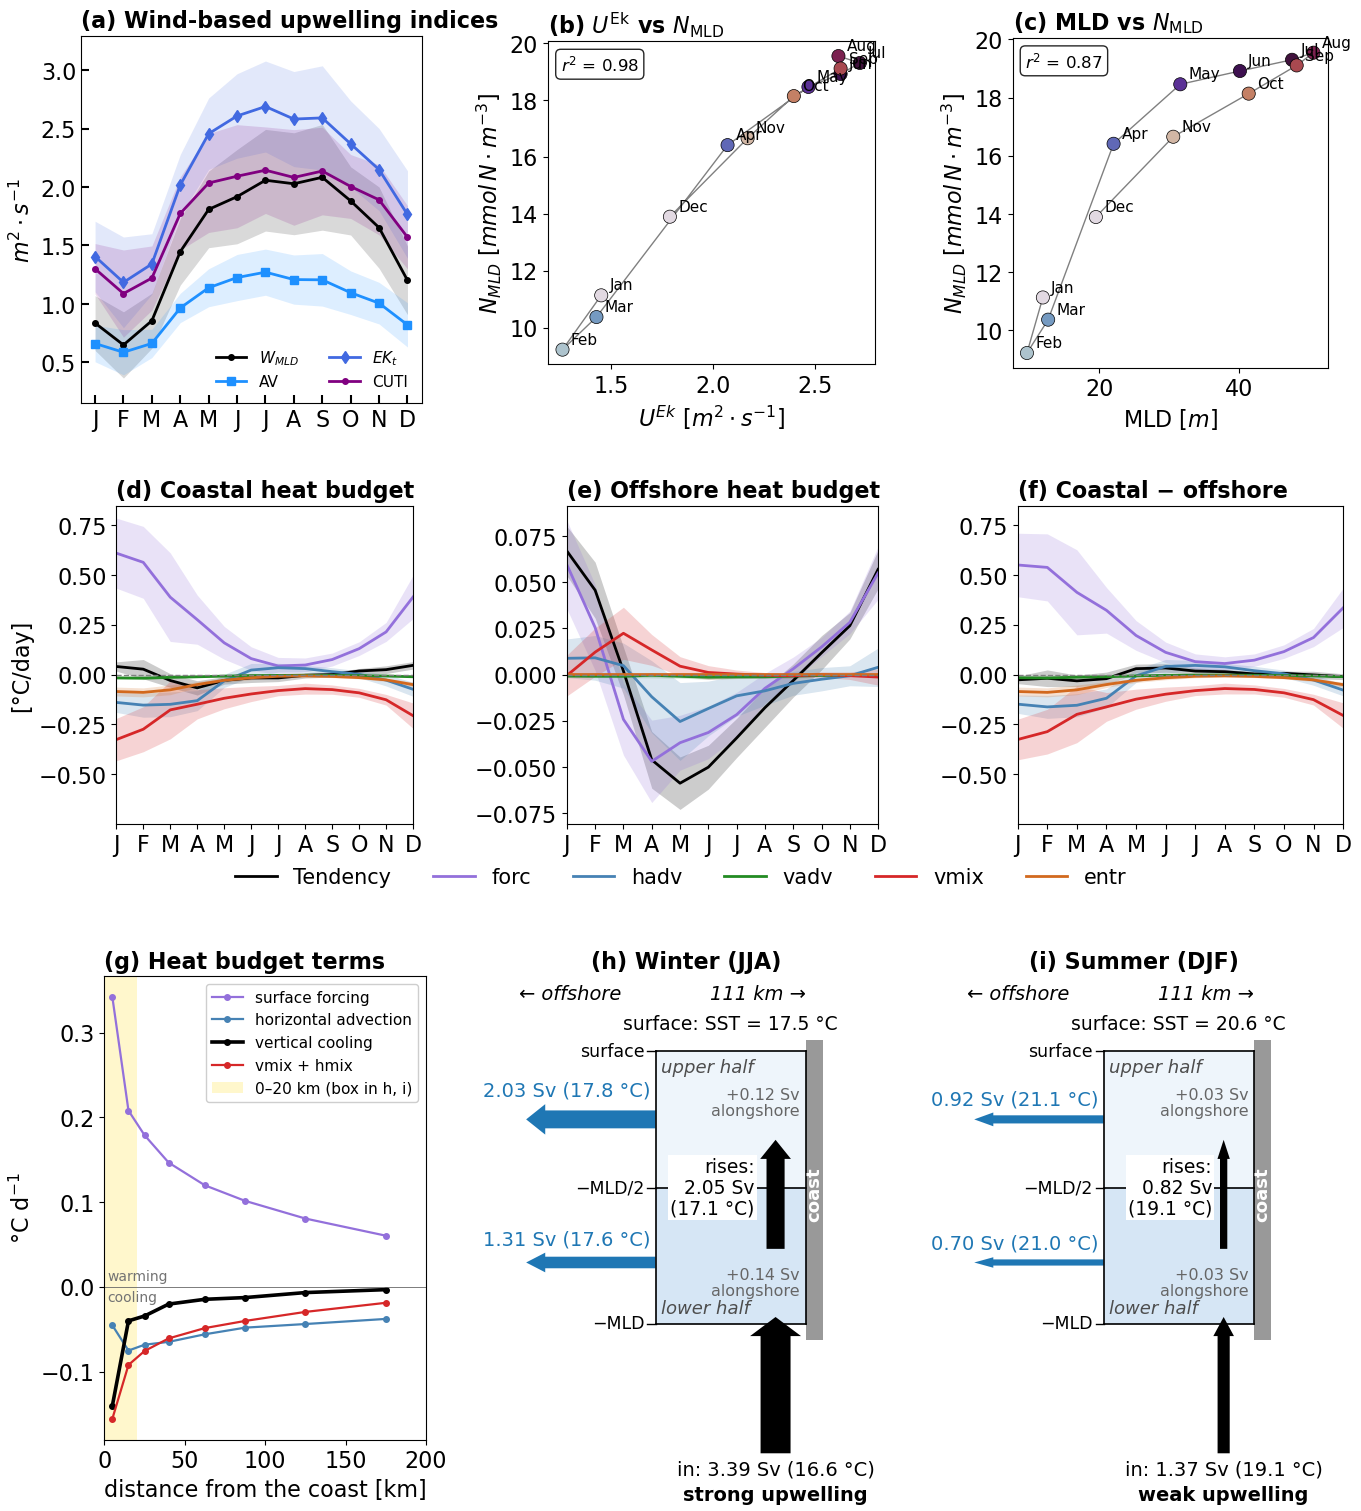

In [23]:
done = False
for gi, geo in enumerate(GEOS):
    for fs_box in BOX_FS:
        fig, parts, stats_N = draw_appendix_C(fs_box, geo, box=BOX_BAND)
        fig.canvas.draw()
        hits = collisions(fig, parts)
        done = not hits or (gi == len(GEOS) - 1 and fs_box == BOX_FS[-1])
        if done:
            break                                 # keep the last attempt open so it is displayed
        plt.close(fig)
    if done:
        break
print(f"1° box: box font size {fs_box} (+ BOX_DFS = {fs_box + BOX_DFS}): "
      + ('no label overlaps an arrow, box edge, depth tick, the coast bar or another label' if not hits
         else f'REMAINING OVERLAPS: {hits}'))

# fig.savefig(FIG / 'Appendix_C_1deg.pdf', bbox_inches='tight')
# fig.savefig(FIG / 'Appendix_C_1deg.png', dpi=300, bbox_inches='tight')
plt.show()